# 02) Exploration des données EHPAD

**Objectif :** comprendre les données avant la modélisation et prendre des décisions concrètes.

Cible : `PRIX_MOIS_HEBPERM_CS_GIR56` (prix mensuel de l'hébergement permanent, chambre seule, GIR 5-6).

Plan :

0. Chargement
1. La cible
2. Le bloc tarification (statut, ASH, mode de fixation des tarifs)
3. Taille et appartenance à un groupe
4. La géographie
5. Les identifiants et les groupes

## 0. Chargement et préparation

In [2]:
import pandas as pd                 
import numpy as np                
import matplotlib.pyplot as plt     
import seaborn as sns               

pd.set_option('display.max_columns', 35)  # Affichage de toutes les colonnes, 35 si je rajoute des intermediaires

In [3]:
df = pd.read_csv('../data/clean/ehpad.csv')
df.shape

(6673, 30)

In [4]:
# Nom court pour la cible, plus pratique à écrire
cible = 'PRIX_MOIS_HEBPERM_CS_GIR56'

# Aperçu des 5 premières lignes
df.head()

,finesset,finessej,PRIX_MOIS_HEBPERM_CS_GIR56,STATUT_JUR,ASH,nb_capins_HP,nb_etab_grp,liblongmft,P19_POP,P19_POP75P,P19_POP75P_perc,loypredm2,nb_communes_epci,P19_POP_epci,P19_POP75P_epci,P19_POP75P_perc_epci,Q219_epci,AGE6Q219_epci,AGE6PPAT19_epci,AGE6PPSOC19_epci,loyer_mean_pondere_epci,REG,DEP,siren,cog,coordx,coordy,anciennete,anciennete_imputee,taux_equip_epci
0,010002228,750057622,3154.8,3-Privé commercial,NON,60,1,"ARS/PCD, Tarif partiel, non habilité aide soci...",14134.0,1239.164308,8.767258,10.074507,53,79063,6079.193731,7.689050,23000.0,22130.0,16.2,1.3,9.810075,84,01,240100883,01004,881334.9,6542456.9,13.0,False,86.853623
1,010004059,010783009,2204.4,2-Privé non lucratif,OUI,66,4,"ARS/PCD, Tarif global, habilité aide sociale s...",4483.0,230.557715,5.142934,20.693334,27,98257,4730.848070,4.814770,36370.0,31890.0,18.3,0.8,19.321257,84,01,240100750,01281,939632.3,6578432.0,11.0,False,80.535243
2,010006799,690802715,2092.2,2-Privé non lucratif,OUI,80,26,"ARS/PCD, Tarif partiel, habilité aide sociale ...",6346.0,680.405938,10.721808,10.984294,18,72815,6745.075392,9.263305,21240.0,22010.0,18.5,1.8,10.212145,84,01,200040590,01194,836009.5,6544033.9,8.0,False,74.721181
3,010008571,010007987,1561.5,1-Public,OUI,69,1,"ARS/PCD, Tarif global, habilité aide sociale, ...",4844.0,765.384953,15.800680,7.996378,42,63365,5266.837161,8.311903,20470.0,21500.0,16.9,1.7,8.814524,84,01,200042935,01185,902289.9,6545912.8,10.0,False,105.756070
4,010009223,010787109,2189.7,2-Privé non lucratif,OUI,75,2,"ARS/PCD, Tarif partiel, habilité aide sociale ...",1241.0,138.000000,11.120064,8.931485,42,63365,5266.837161,8.311903,20470.0,21500.0,16.9,1.7,8.814524,84,01,200042935,01181,900979.5,6572377.3,3.0,False,105.756070


## 1. La cible : le prix

In [5]:
# moyenne, écart-type, min, quartiles , max
df[cible].describe()

count    6673.000000
mean     2172.792957
std       522.016494
min      1097.700000
25%      1836.000000
50%      1999.500000
75%      2375.100000
max      7284.000000
Name: PRIX_MOIS_HEBPERM_CS_GIR56, dtype: float64

> **Analyse :** la moyenne (2 173 €) est au-dessus de la médiane (2 000 €).  Des établissements chers tirent la moyenne vers le haut. 
La moitié des EHPAD se situe entre 1 836 € et 2 375 €, mais le maximum monte à 7 284 €.

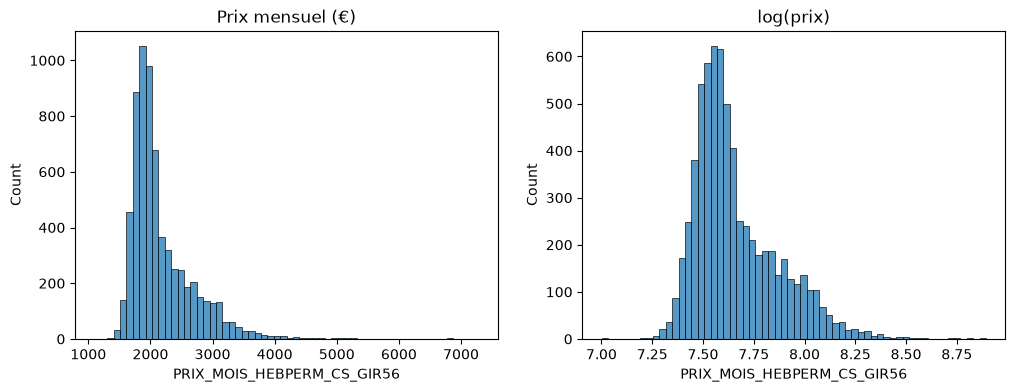

In [6]:
# Graphique distributin
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# À gauche : le prix brut
sns.histplot(df[cible], bins=60, ax=axes[0])
axes[0].set_title('Prix mensuel (€)')

# À droite : le log du prix, pour voir si la disitrbution devient plus symétrique
sns.histplot(np.log(df[cible]), bins=60, ax=axes[1])
axes[1].set_title('log(prix)')
plt.show()

In [7]:
# calcul de l'asymétrie
print('Asymétrie prix brut :', df[cible].skew())
print('Asymétrie log(prix) :', np.log(df[cible]).skew())

Asymétrie prix brut : 2.188533960077316
Asymétrie log(prix) : 1.1755316734577712


> Le log réduit l'asymétrie de moitié (2,19 → 1,18) sans la supprimer. Passer la cible au log est donc utile, surtout pour un modèle linéaire. Pour un modèle à base d'arbres (Random Forest, Gradient Boosting), c'est moins important.

In [8]:
# Analyse à l'oeil des valeurs les plus élevés
df.sort_values(cible, ascending=False)[[cible, 'STATUT_JUR', 'ASH', 'DEP']].head(10)

,PRIX_MOIS_HEBPERM_CS_GIR56,STATUT_JUR,ASH,DEP
5266,7284.0,3-Privé commercial,NON,75
5231,7077.6,3-Privé commercial,NON,75
5223,6791.7,3-Privé commercial,OUI,75
5244,6790.2,3-Privé commercial,NON,75
5264,6252.9,3-Privé commercial,OUI,75
6424,6137.7,3-Privé commercial,NON,92
5252,6040.2,3-Privé commercial,NON,75
6466,5383.2,3-Privé commercial,NON,92
5278,5318.1,3-Privé commercial,NON,75
5274,5289.6,3-Privé commercial,NON,75


> Les 10 prix les plus élevés sont **tous privés commerciaux** et tous à Paris (75) ou dans les Hauts-de-Seine (92).

In [9]:
#  Analyse à l'oeil des valeurs les plus faibles
df.sort_values(cible, ascending=True)[[cible, 'STATUT_JUR', 'ASH', 'DEP']].head(10)

,PRIX_MOIS_HEBPERM_CS_GIR56,STATUT_JUR,ASH,DEP
2552,1097.7,2-Privé non lucratif,OUI,38
1978,1368.3,2-Privé non lucratif,OUI,32
4927,1388.4,1-Public,OUI,70
4391,1402.8,1-Public,OUI,63
924,1410.0,3-Privé commercial,NON,16
2421,1417.2,1-Public,NON,36
2649,1422.0,1-Public,OUI,40
373,1432.8,2-Privé non lucratif,OUI,07
2671,1441.8,1-Public,OUI,40
587,1454.4,1-Public,OUI,12


> Les prix les plus bas sont surtout publics ou associatifs habilités ASH, dans des départements ruraux. Le minimum (1 098 €, Isère) est isolé mais reste plausible. Rien à supprimer.

## 2. Le bloc tarification : `STATUT_JUR`, `ASH`, `liblongmft`

In [10]:
# Prix par statut juridique : effectif, médiane et moyenne
df.groupby('STATUT_JUR')[cible].agg(['count', 'median', 'mean']).round(2)

,count,median,mean
STATUT_JUR,,,
1-Public,2952,1867.80,1881.72
2-Privé non lucratif,2050,2010.45,2069.92
3-Privé commercial,1671,2722.80,2813.21


> le statut juridique sépare très nettement les prix. Le privé commercial est environ **850 € plus cher** que le public en médiane (2 723 € contre 1 868 €). Le privé non lucratif se place entre les deux, plus près du public.

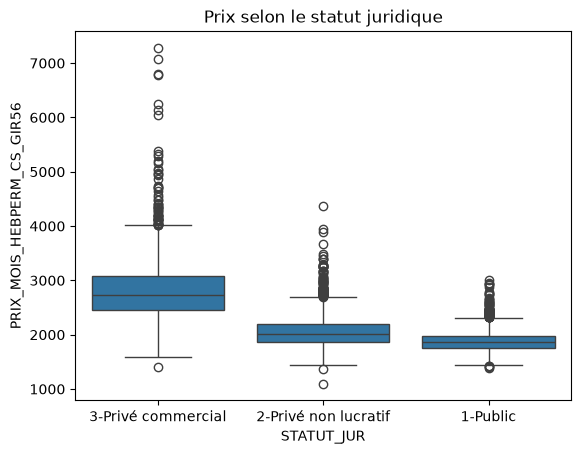

In [11]:
# Boîte à moustaches du prix selon le statut
sns.boxplot(data=df, x='STATUT_JUR', y=cible)
plt.title('Prix selon le statut juridique')
plt.show()

In [12]:
# Prix selon l'habilitation à l'aide sociale (ASH)
df.groupby('ASH')[cible].agg(['count', 'median', 'mean']).round(2)

,count,median,mean
ASH,,,
NON,1248,2675.1,2741.08
OUI,5425,1942.5,2042.06


In [13]:
# Croisement statut x ASH et affuchage de la médiane
pd.crosstab(df['STATUT_JUR'], df['ASH'], values=df[cible], aggfunc='median').round(2)

ASH,NON,OUI
STATUT_JUR,,
1-Public,2040.45,1867.50
2-Privé non lucratif,2255.40,1995.15
3-Privé commercial,2792.25,2658.30


>  à statut égal, ne pas être habilité ASH ne coûte que 130 à 260 € de plus, alors que l'écart entre public et commercial atteint environ 770 € : c'est surtout le statut qui fait le prix.

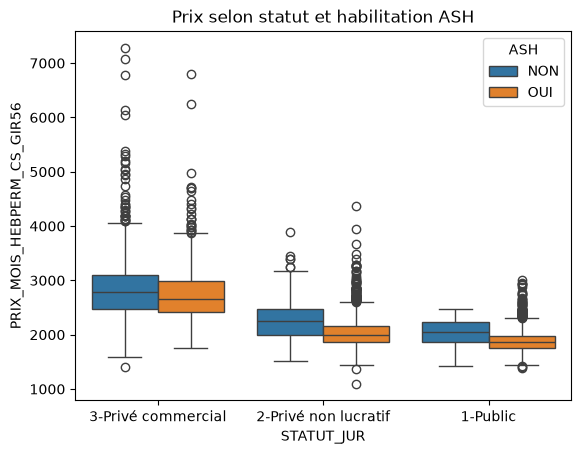

In [14]:
# boite à moustache du prix x statut en fonction de l'ash
sns.boxplot(data=df, x='STATUT_JUR', y=cible, hue='ASH')
plt.title('Prix selon statut et habilitation ASH')
plt.show()

> les effectifs sont très déséquilibrés. 98 % des EHPAD publics sont habilités ASH, alors que 60 % des commerciaux ne le sont pas. Statut et ASH sont donc liés, mais pas entièrement : les 657 commerciaux habilités et les 212 associatifs non habilités apportent une vraie information. On garde les deux variables.

`liblongmft` a beaucoup de modalités, certaines très rares. Regardons les effectifs.

In [15]:
# Nombre d'établissements par mode de fixation des tarifs
df['liblongmft'].value_counts()

liblongmft
ARS/PCD, Tarif partiel, habilité aide sociale sans PUI          3477
ARS/PCD, Tarif partiel, non habilité aide sociale sans PUI      1045
ARS/PCD, Tarif global, habilité aide sociale, recours PUI       1021
ARS/PCD, Tarif global, habilité aide sociale sans PUI            803
ARS/PCD, Tarif global, non habilité aide sociale sans PUI        176
ARS/PCD, Tarif partiel, habilité aide sociale, recours PUI       109
ARS/PCD, PUV, forfait soins, habilité aide sociale                 8
ARS/PCD, PUV, forfait soins, non habilité aide sociale             8
ARS/PCD, Tarif global, non hab.aide sociale, recours PUI           8
ARS/PCD, PUV, convention SSIAD, habilité à l'aide sociale          7
ARS/PCD, PUV, convention SSIAD, non habilité à l'aide social       4
ARS/PCD, Tarif partiel, non hab.aide sociale, recours PUI          3
Indéterminé                                                        2
ARS établissements Publics de santé dotation globale               2
Name: count, dtype: int

In [16]:
# Est-ce que liblongmft apporte quelque chose de plus que ASH ?
# On croise les deux : si chaque modalité de liblongmft tombe dans une seule colonne ASH,
# alors la partie 'habilité / non habilité' de liblongmft est redondante.
pd.crosstab(df['liblongmft'], df['ASH'])

ASH,NON,OUI
liblongmft,,
ARS établissements Publics de santé dotation globale,2,0
"ARS/PCD, PUV, convention SSIAD, habilité à l'aide sociale",0,7
"ARS/PCD, PUV, convention SSIAD, non habilité à l'aide social",4,0
"ARS/PCD, PUV, forfait soins, habilité aide sociale",0,8
"ARS/PCD, PUV, forfait soins, non habilité aide sociale",8,0
"ARS/PCD, Tarif global, habilité aide sociale sans PUI",0,803
"ARS/PCD, Tarif global, habilité aide sociale, recours PUI",0,1021
"ARS/PCD, Tarif global, non hab.aide sociale, recours PUI",8,0
"ARS/PCD, Tarif global, non habilité aide sociale sans PUI",176,0


> L'information "habilité à l'aide sociale" tombe entièrement à droite et "non habilité" à gauche donc les deux colonnes se recoupent -> redondance de l'info

In [17]:
# On vérifie une info que ASH n'a pas : tarif 'global' ou 'partiel' -> p-ê lié à l'hébergement ou aux soins

df['tarif_global'] = df['liblongmft'].str.contains('global')

# Prix médian selon tarif global ou non, séparé par ASH
pd.crosstab(df['tarif_global'], df['ASH'], values=df[cible], aggfunc='median').round(2)

ASH,NON,OUI
tarif_global,,
False,2657.85,1964.40
True,2732.25,1903.65


> La variation du prix est minime et surtout elle n'évolue pas dans le même sens en fonction de Ash = Oui ou Non. Probablement du bruit, on peut supprimer `liblongmft`

In [18]:
#Suppression des colonnes qui ne seront pas utilisés dans le modèle
df = df.drop(columns=['tarif_global', 'liblongmft'])

## 3. Taille et appartenance à un groupe

In [19]:
# Statistiques de la capacité et du nombre d'établissements du groupe
df[['nb_capins_HP', 'nb_etab_grp']].describe().round(0)

,nb_capins_HP,nb_etab_grp
count,6673.0,6673.0
mean,80.0,11.0
std,40.0,31.0
min,1.0,1.0
25%,60.0,1.0
50%,76.0,1.0
75%,90.0,4.0
max,525.0,174.0


>  la capacité est assez concentrée (moitié des EHPAD entre 60 et 90 places), avec quelques très grosses structures (525 places). `nb_etab_grp` est très asymétrique : au moins la moitié des EHPAD sont isolés (médiane = 1), mais certains groupes en comptent 174.

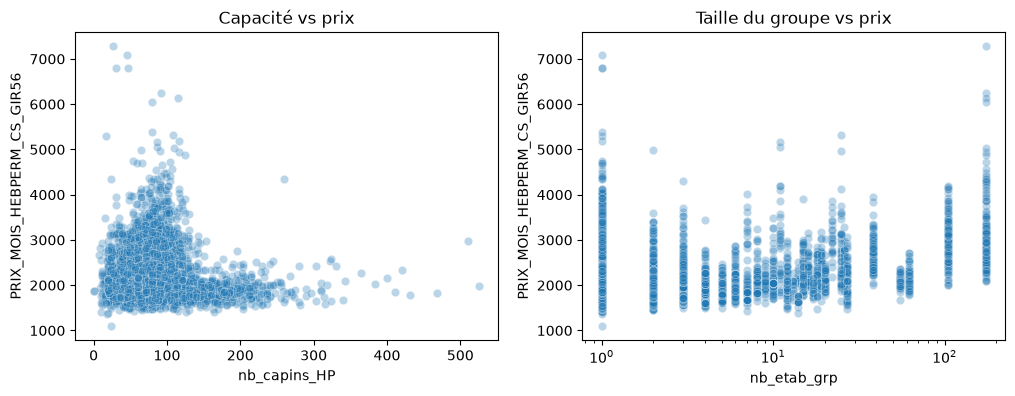

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Capacité contre prix
sns.scatterplot(data=df, x='nb_capins_HP', y=cible, alpha=0.3, ax=axes[0])
axes[0].set_title('Capacité vs prix')

# Taille du groupe contre prix, en échelle log sur l'axe x car très étalée
sns.scatterplot(data=df, x='nb_etab_grp', y=cible, alpha=0.3, ax=axes[1])
axes[1].set_xscale('log')
axes[1].set_title('Taille du groupe vs prix')

plt.show()

>  les nuages de points ne montrent pas de lien clair entre capacité et prix. Pour la taille du groupe, les prix élevés semblent plus fréquents dans les gros groupes, mais c'est sans doute l'effet du statut commercial (les grands groupes sont surtout commerciaux).

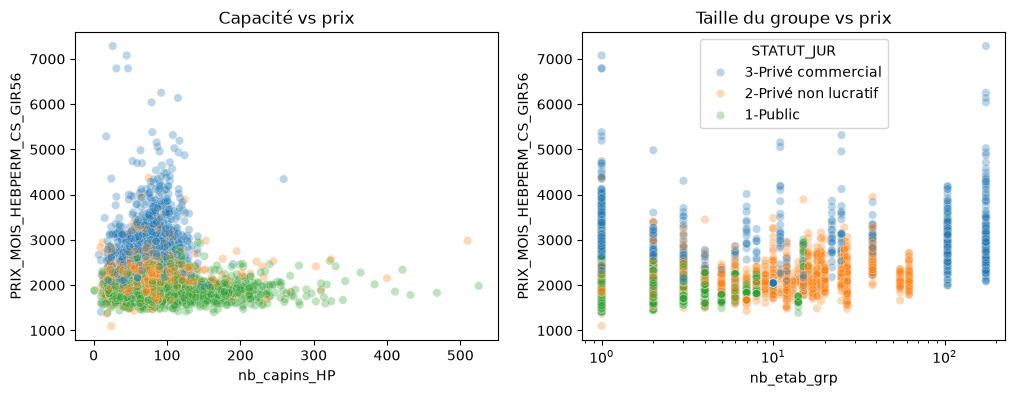

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Capacité contre prix, points colorés selon le statut juridique
sns.scatterplot(data=df, x='nb_capins_HP', y=cible, hue='STATUT_JUR',
                alpha=0.3, ax=axes[0], legend=False)   # pas de légende ici, pour ne pas l'afficher deux fois
axes[0].set_title('Capacité vs prix')

# Taille du groupe contre prix, en échelle log sur l'axe x car très étalée
sns.scatterplot(data=df, x='nb_etab_grp', y=cible, hue='STATUT_JUR',
                alpha=0.3, ax=axes[1])                 # la légende des couleurs s'affiche sur ce graphique
axes[1].set_xscale('log')
axes[1].set_title('Taille du groupe vs prix')

plt.show()

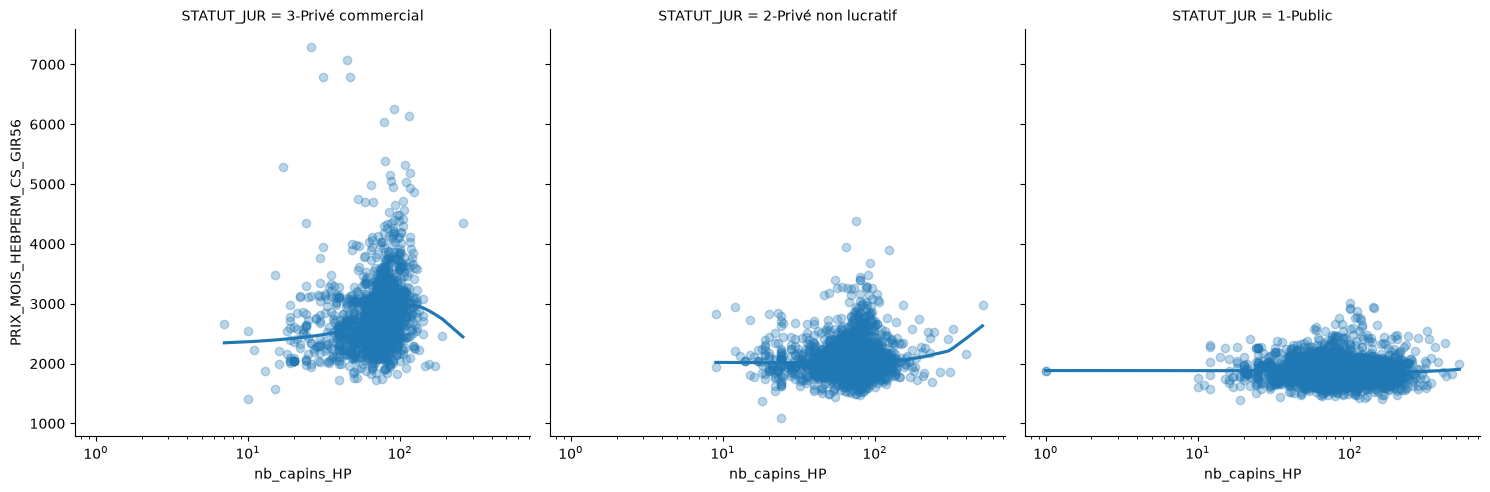

In [22]:
g = sns.lmplot(data=df, x="nb_capins_HP", y="PRIX_MOIS_HEBPERM_CS_GIR56",
               col="STATUT_JUR", lowess=True,
               scatter_kws={"alpha": 0.3})
g.set(xscale="log")
plt.show()

In [23]:
# Variable simple : l'établissement est-il isolé (1 seul) ou dans un groupe ?
df['en_groupe'] = df['nb_etab_grp'] > 1

# Prix médian selon isolé/groupe, pour chaque statut
pd.crosstab(df['STATUT_JUR'], df['en_groupe'], values=df[cible], aggfunc='median').round(0)

en_groupe,False,True
STATUT_JUR,,
1-Public,1862.0,1880.0
2-Privé non lucratif,1939.0,2063.0
3-Privé commercial,2660.0,2890.0


groupe_label          En groupe  Isolé
STATUT_JUR                            
1-Public                   1060   1892
2-Privé non lucratif       1265    785
3-Privé commercial          547   1124


C:\Users\trist\AppData\Local\Temp\ipykernel_22888\3006995289.py:7: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=df, x='STATUT_JUR', y=cible, hue='groupe_label',


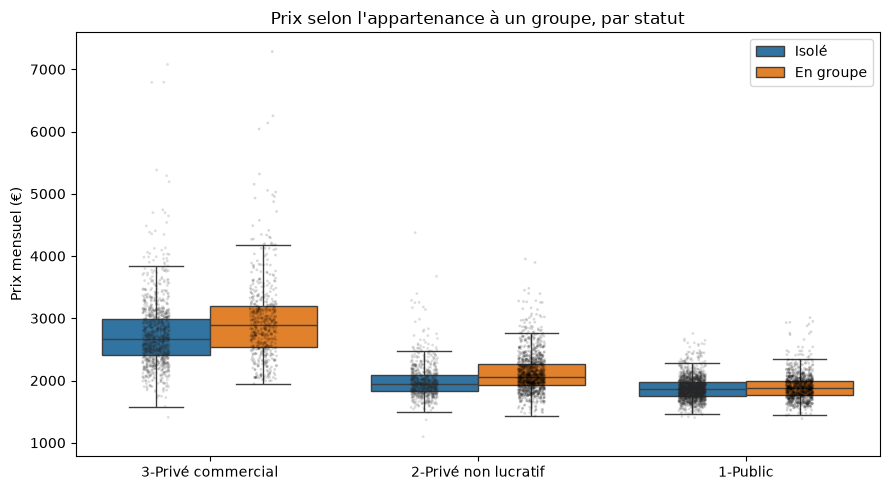

In [24]:
df['groupe_label'] = df['en_groupe'].map({True: 'En groupe', False: 'Isolé'})

plt.figure(figsize=(9, 5))
ax = sns.boxplot(data=df, x='STATUT_JUR', y=cible, hue='groupe_label',
                 hue_order=['Isolé', 'En groupe'], showfliers=False)

sns.stripplot(data=df, x='STATUT_JUR', y=cible, hue='groupe_label',
              hue_order=['Isolé', 'En groupe'], dodge=True,
              alpha=0.15, size=2, color='black', legend=False, ax=ax)

effectifs = pd.crosstab(df['STATUT_JUR'], df['groupe_label'])
print(effectifs)

ax.set_title("Prix selon l'appartenance à un groupe, par statut")
ax.set_xlabel("")
ax.set_ylabel("Prix mensuel (€)")
ax.legend(title="")
plt.tight_layout()
plt.show()

>  à statut égal, appartenir à un groupe compte peu pour le public (+18 €). L'écart est plus marqué pour l'associatif (+124 €) et le commercial (+230 €). La version binaire `en_groupe` est simple et capte l'essentiel : c'est une bonne candidate pour remplacer `nb_etab_grp`.

## 3 bis. Nouvelles variables : ancienneté et taux d'équipement

Deux variables ajoutées dans le notebook 01 :
- `anciennete` : années depuis l'ouverture de l'établissement (dates par défaut 1901 et 1904 mises en manquant) ;
- `taux_equip_epci` : places d'EHPAD pour 1 000 personnes de 75 ans et plus dans l'EPCI.

In [25]:
# Statistiques des deux nouvelles variables
df[['anciennete', 'taux_equip_epci']].describe().round(1)

,anciennete,taux_equip_epci
count,6673.0,6673.0
mean,32.1,98.4
std,19.8,39.1
min,0.0,18.8
25%,20.0,69.8
50%,29.0,89.7
75%,41.0,117.4
max,213.0,298.7


In [26]:
df[['finesset','anciennete']].nlargest(10, 'anciennete')

,finesset,anciennete
6101,860780733,213.0
2019,330781428,192.0
3370,500004718,171.0
2039,330782756,169.0
2057,330786187,169.0
5271,750800526,165.0
1440,250004322,145.0
1389,240007450,144.0
6303,900003260,137.0
409,080003312,128.0


>l'ancienneté médiane est de 29 ans, de 0 (ouverture en 2019) à plus de 200 ans pour d'anciens hospices. Elle est connue pour 5 857 EHPAD sur 6 673 : **816 valeurs manquantes**. Le taux d'équipement varie beaucoup selon les territoires, de 19 à 299 places pour 1 000 personnes de 75 ans et plus (médiane : 90).

In [27]:
# Découper l'ancienneté en tranches pour lire plus facilement l'effet sur le prix
tranches = [0, 10, 20, 30, 50, 300]                          # bornes des tranches, en années
noms = ['< 10 ans', '10-20 ans', '20-30 ans', '30-50 ans', '50 ans et +']
df['tranche_anciennete'] = pd.cut(df['anciennete'], bins=tranches, labels=noms,
                                  include_lowest=True)        # include_lowest : inclure les EHPAD de 0 an

# Effectif et prix médian par tranche
df.groupby('tranche_anciennete', observed=True)[cible].agg(['count', 'median']).round(0)

,count,median
tranche_anciennete,,
< 10 ans,831,2210.0
10-20 ans,851,2215.0
20-30 ans,2334,1994.0
30-50 ans,1779,1934.0
50 ans et +,878,1908.0


In [28]:
# Même lecture, séparée par statut : l'effet tient-il à statut égal ?
pd.crosstab(df['tranche_anciennete'], df['STATUT_JUR'], values=df[cible], aggfunc='median').round(0)

STATUT_JUR,1-Public,2-Privé non lucratif,3-Privé commercial
tranche_anciennete,,,
< 10 ans,1951.0,2110.0,2879.0
10-20 ans,1916.0,2094.0,2860.0
20-30 ans,1856.0,1997.0,2666.0
30-50 ans,1853.0,1974.0,2560.0
50 ans et +,1848.0,1940.0,2740.0


> l'effet attendu est bien là. Les EHPAD de moins de 20 ans sont autour de 2 220 € en médiane, ceux de plus de 30 ans autour de 1 920 €, soit environ 300 € d'écart.
>
> À statut égal, l'effet reste visible mais plus modéré : environ 100 € pour le public, 170 € pour l'associatif, 300 € pour le commercial entre les plus récents et les 30-50 ans. Le commercial de plus de 50 ans remonte : ce sont sans doute quelques établissements de prestige en centre-ville, et l'effectif est faible. **L'ancienneté apporte une information propre, surtout dans le privé.**

In [29]:
# Découper le taux d'équipement en 4 groupes de même taille (quartiles)
df['quartile_equip'] = pd.qcut(df['taux_equip_epci'], 4,
                               labels=['Q1 (peu de places)', 'Q2', 'Q3', 'Q4 (beaucoup de places)'])

# Prix médian par quartile
df.groupby('quartile_equip', observed=True)[cible].median().round(0)

quartile_equip
Q1 (peu de places)         2278.0
Q2                         2046.0
Q3                         1955.0
Q4 (beaucoup de places)    1873.0
Name: PRIX_MOIS_HEBPERM_CS_GIR56, dtype: float64

>  plus un territoire a de places, moins les prix sont élevés : 2 278 € en médiane dans le quart le moins équipé, 1 873 € dans le plus équipé. C'est cohérent avec une logique de concurrence.

In [30]:
# Mais les territoires peu équipés sont souvent des villes chères. Le taux d'équipement
# n'est-il qu'un reflet du loyer ? Corrélation entre les deux :
print('Corrélation taux d\'équipement / loyer :', round(df['taux_equip_epci'].corr(df['loypredm2']), 2))

# Prix médian selon le loyer (lignes) et le taux d'équipement (colonnes), en quartiles
df['quartile_loyer'] = pd.qcut(df['loypredm2'], 4, labels=['L1 (bas)', 'L2', 'L3', 'L4 (haut)'])
pd.crosstab(df['quartile_loyer'], df['quartile_equip'], values=df[cible], aggfunc='median').round(0)

Corrélation taux d'équipement / loyer : -0.42


quartile_equip,Q1 (peu de places),Q2,Q3,Q4 (beaucoup de places)
quartile_loyer,,,,
L1 (bas),1875.0,1882.0,1844.0,1843.0
L2,1974.0,1958.0,1919.0,1882.0
L3,2054.0,2063.0,2025.0,1918.0
L4 (haut),2563.0,2309.0,2236.0,2629.0


> le taux d'équipement est assez corrélé au loyer (−0,42) : les villes chères ont moins de places par habitant âgé. Une bonne partie de son lien avec le prix passe donc par le loyer.
>
> À loyer égal (en lisant une ligne du tableau), l'effet propre est faible : quasi nul pour les loyers bas, autour de 100 à 140 € pour les loyers moyens. Pour les loyers les plus hauts, le tableau n'est pas régulier, et certaines cases comptent peu d'EHPAD.
>
>  variable à garder et à tester en modélisation, mais son apport sera probablement modeste une fois le loyer présent.

**À retenir (nouvelles variables) :** l'ancienneté apporte une vraie information, surtout dans le privé ; ses 816 manquants (surtout publics) sont informatifs et méritent une colonne indicatrice. Le taux d'équipement va dans le sens attendu, mais il recoupe en grande partie le loyer.

## 4. Le territoire : commune contre EPCI

In [31]:
# Liste des variables territoriales numériques
territoire = [
    'P19_POP', 'P19_POP75P', 'P19_POP75P_perc', 'loypredm2',
    'nb_communes_epci', 'P19_POP_epci', 'P19_POP75P_epci', 'P19_POP75P_perc_epci',
    'Q219_epci', 'AGE6Q219_epci', 'AGE6PPAT19_epci', 'AGE6PPSOC19_epci',
    'loyer_mean_pondere_epci',
]

# Corrélation de chaque variable avec le prix, triée de la plus forte à la plus faible
df[territoire + [cible]].corr()[cible].drop(cible).sort_values(ascending=False).round(2)

loypredm2                  0.64
loyer_mean_pondere_epci    0.61
AGE6Q219_epci              0.50
P19_POP75P_epci            0.47
P19_POP_epci               0.46
AGE6PPAT19_epci            0.42
Q219_epci                  0.34
nb_communes_epci           0.29
P19_POP75P                 0.24
P19_POP                    0.23
AGE6PPSOC19_epci           0.09
P19_POP75P_perc           -0.28
P19_POP75P_perc_epci      -0.31
Name: PRIX_MOIS_HEBPERM_CS_GIR56, dtype: float64

> **Potentiels candidats à garder :**
> - `loypredm2` (0,64)
> - `AGE6Q219_epci` (0,50)
> - `P19_POP_epci` (0,46)
> - `AGE6PPAT19_epci` (0,42)
> - `P19_POP75P_perc_epci` (−0,31)

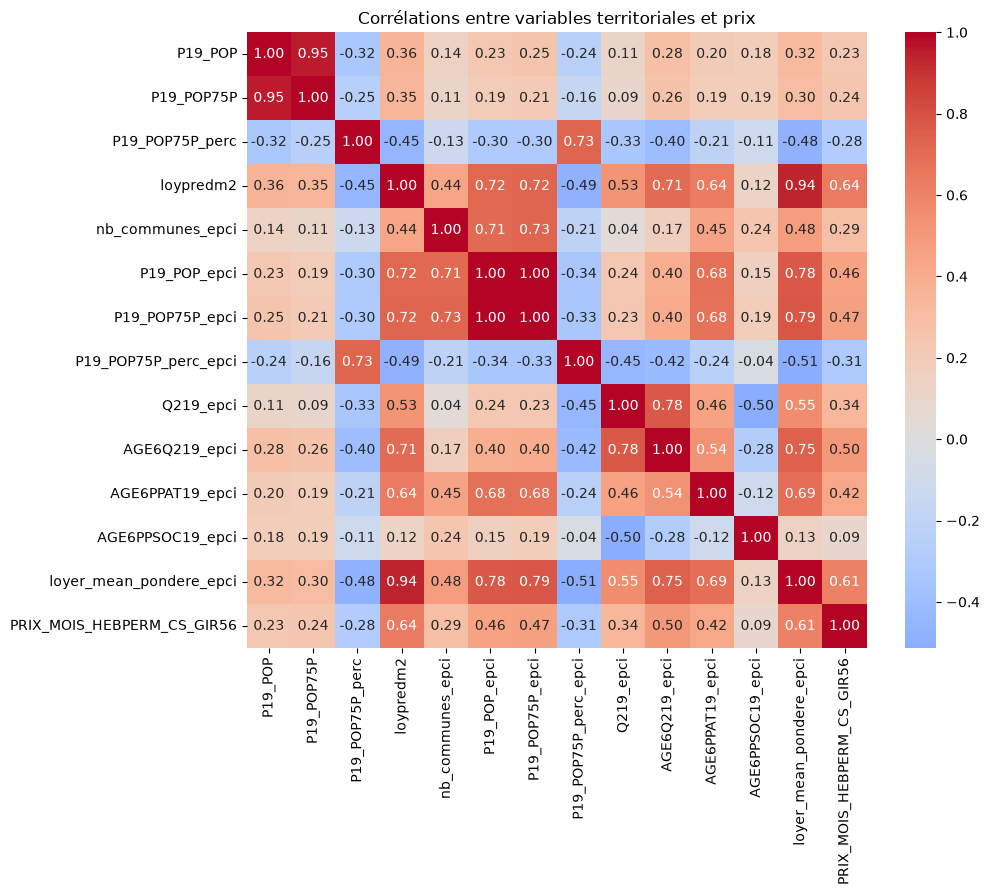

In [32]:
# Matrice de corrélation complète, sous forme de carte de chaleur
plt.figure(figsize=(10, 8))
sns.heatmap(df[territoire + [cible]].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Corrélations entre variables territoriales et prix')
plt.show()

>  la carte de chaleur confirme deux blocs de variables très liées : les populations brutes (population totale et nombre de 75+, qui se suivent presque parfaitement) et les loyers. Les effectifs bruts de 75+ (`P19_POP75P`, `P19_POP75P_epci`) font doublon avec la population : on peut les retirer et garder les parts (`_perc`).

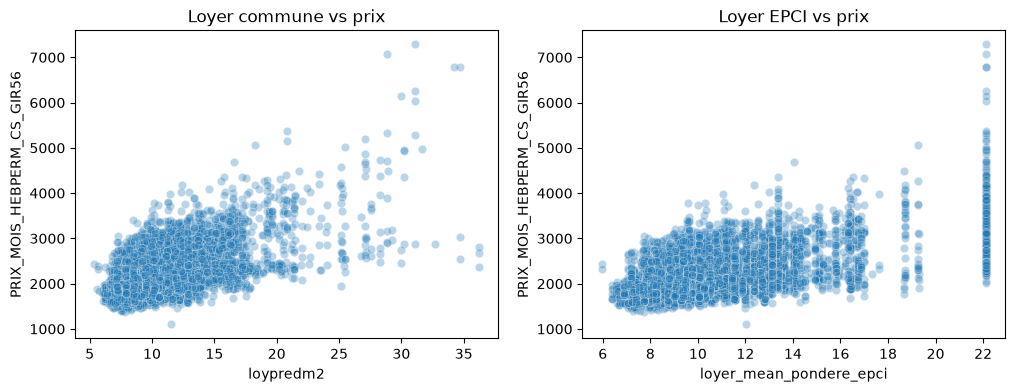

In [33]:
# Le loyer est sans doute le meilleur indicateur : prix vs loyer, commune et EPCI
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x='loypredm2', y=cible, alpha=0.3, ax=axes[0])
axes[0].set_title('Loyer commune vs prix')
sns.scatterplot(data=df, x='loyer_mean_pondere_epci', y=cible, alpha=0.3, ax=axes[1])
axes[1].set_title('Loyer EPCI vs prix')
plt.show()

>  le prix augmente bien avec le loyer, mais le nuage s'élargit fortement pour les loyers élevés. Dans les zones chères, on trouve à la fois des EHPAD publics bon marché et des commerciaux très chers. Le loyer explique le niveau général ; le statut explique l'écart à l'intérieur d'un même territoire.

## 5. La géographie

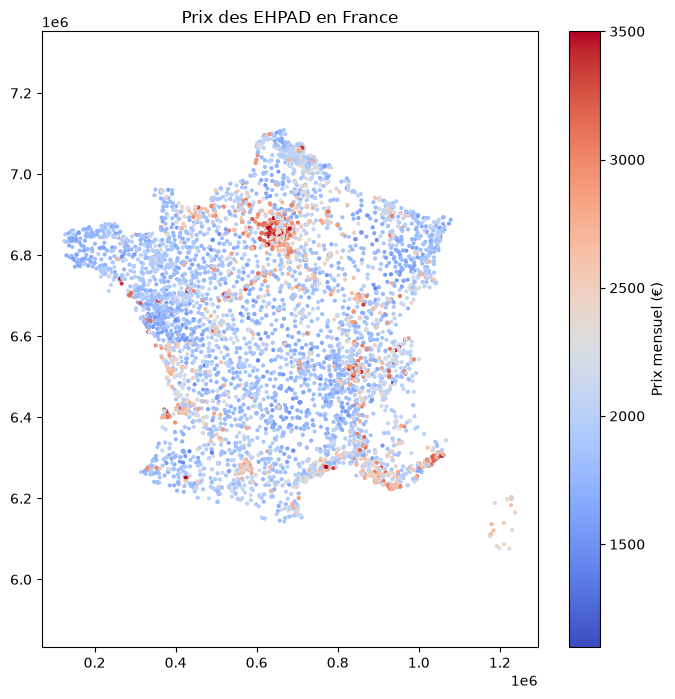

In [34]:
# Carte simple : chaque point est un EHPAD, la couleur indique le prix
plt.figure(figsize=(8, 8))
plt.scatter(df['coordx'], df['coordy'], c=df[cible], cmap='coolwarm', s=4, vmax=3500)
plt.colorbar(label='Prix mensuel (€)')   # légende des couleurs
plt.axis('equal')                         # garder les proportions de la carte
plt.title('Prix des EHPAD en France')
plt.show()

> la carte fait ressortir l'Île-de-France, la Côte d'Azur, la Corse et les grandes métropoles (Lyon, Bordeaux, Toulouse). Le reste du territoire est assez homogène et moins cher. L'effet géographique suit largement celui du loyer, déjà présent dans les variables territoriales.

In [35]:
# Prix médian et effectif par région, du plus cher au moins cher
df.groupby('REG')[cible].agg(['count', 'median']).sort_values('median', ascending=False).round(0)

,count,median
REG,,
11,623,2768.0
94,22,2470.0
93,512,2422.0
32,532,2040.0
76,722,1994.0
27,382,1974.0
84,877,1973.0
28,352,1958.0
75,838,1956.0


>  l'Île-de-France (11) est nettement au-dessus (2 768 €), suivie de la Corse (94) et de PACA (93). Les autres régions sont serrées entre 1 860 € et 2 040 €. Attention, la Corse ne compte que 22 EHPAD : sa médiane est moins fiable.

In [36]:
# Nombre de départements et effectif minimum par département
par_dep = df['DEP'].value_counts()
print('Nombre de départements :', par_dep.size)
print('Plus petit effectif :', par_dep.min())

Nombre de départements : 96
Plus petit effectif : 10


> 96 départements, tous avec au moins 10 EHPAD : pas de département vide. Mais encoder `DEP` en one-hot créerait 96 colonnes, ce qui est lourd. `REG` (13 modalités) est plus simple, et une grande partie de l'effet territorial est déjà captée par le loyer.

In [37]:
# Les 10 départements les plus chers (prix médian)
df.groupby('DEP')[cible].median().sort_values(ascending=False).head(10).round(0)

DEP
92    3264.0
75    3232.0
78    3018.0
95    2802.0
06    2791.0
91    2658.0
93    2600.0
77    2530.0
2B    2481.0
13    2474.0
Name: PRIX_MOIS_HEBPERM_CS_GIR56, dtype: float64

>  le top 10 est dominé par l'Île-de-France (92, 75, 78, 95, 91, 93, 77), puis les Alpes-Maritimes (06), la Haute-Corse (2B) et les Bouches-du-Rhône (13). Cela confirme que la géographie reflète surtout la pression immobilière.

### 5 bis. Le poids du département

Pour les EHPAD habilités à l'aide sociale, le tarif d'hébergement est fixé par le **conseil départemental**. Le département pourrait donc être un facteur direct du prix, et pas seulement un repère géographique.

**Méthode :** on remplace le prix de chaque EHPAD par le prix moyen de son groupe (son département, sa région ou son statut), puis on mesure la part des écarts de prix ainsi expliquée. 0 = le groupe n'explique rien ; 1 = il explique tout.

In [38]:
# Fonction : part des écarts de prix expliquée par un regroupement (de 0 à 1)
def part_expliquee(data, groupe):
    moyenne_groupe = data.groupby(groupe)[cible].transform('mean')      # prix moyen du groupe de chaque EHPAD
    ecarts_restants = ((data[cible] - moyenne_groupe) ** 2).sum()       # écarts non expliqués par le groupe
    ecarts_totaux = ((data[cible] - data[cible].mean()) ** 2).sum()     # écarts à la moyenne générale
    return round(1 - ecarts_restants / ecarts_totaux, 2)

# Sous-ensembles à comparer
sous_ensembles = {
    'Tous les EHPAD':      df,
    'Habilités ASH':       df[df['ASH'] == 'OUI'],
    'Non habilités ASH':   df[df['ASH'] == 'NON'],
    'Publics':             df[df['STATUT_JUR'] == '1-Public'],
    'Privés commerciaux':  df[df['STATUT_JUR'] == '3-Privé commercial'],
}

# Pour chaque sous-ensemble : part expliquée par le département, la région et le statut
for nom, data in sous_ensembles.items():
    print(f'{nom:20} ({len(data)} EHPAD) | DEP : {part_expliquee(data, 'DEP')}'
          f' | REG : {part_expliquee(data, 'REG')} | statut : {part_expliquee(data, 'STATUT_JUR')}')

Tous les EHPAD       (6673 EHPAD) | DEP : 0.42 | REG : 0.28 | statut : 0.53
Habilités ASH        (5425 EHPAD) | DEP : 0.44 | REG : 0.26 | statut : 0.48
Non habilités ASH    (1248 EHPAD) | DEP : 0.47 | REG : 0.21 | statut : 0.15
Publics              (2952 EHPAD) | DEP : 0.53 | REG : 0.24 | statut : 0.0
Privés commerciaux   (1671 EHPAD) | DEP : 0.55 | REG : 0.28 | statut : 0.0


> 
> - Sur l'ensemble des EHPAD, le département explique **42 %** des écarts de prix, contre 28 % pour la région. C'est presque autant que le statut juridique (53 %), notre meilleure variable.
> - Chez les **publics**, où le statut ne joue plus, le département explique **53 %** des écarts. C'est cohérent avec une tarification fixée département par département.
> - Chez les **commerciaux**, il explique aussi 55 %. Pour eux, ce n'est pas la tarification mais le marché local : le département capte alors surtout le niveau des prix immobiliers.
> - La région fait systématiquement deux fois moins bien : elle mélange des départements très différents (Paris et la Seine-et-Marne, par exemple).
>
> Avec 96 départements, le calcul surestime légèrement l'effet (chaque groupe « colle » un peu à ses propres données), mais avec 6 673 EHPAD ce biais reste faible.

In [39]:
# EHPAD habilités à l'aide sociale
hab = df[df['ASH'] == 'OUI']

# Écart entre départements : prix médian des EHPAD habilités dans chaque département
prix_dep = hab.groupby('DEP')[cible].median().sort_values()

print('3 départements les moins chers :')
print(prix_dep.head(3).round(0))
print('3 départements les plus chers :')
print(prix_dep.tail(3).round(0))
print('Plus petit nombre d\'EHPAD habilités dans un département :', hab['DEP'].value_counts().min())


3 départements les moins chers :
DEP
70    1628.0
55    1675.0
88    1678.0
Name: PRIX_MOIS_HEBPERM_CS_GIR56, dtype: float64
3 départements les plus chers :
DEP
06    2632.0
92    2947.0
75    2978.0
Name: PRIX_MOIS_HEBPERM_CS_GIR56, dtype: float64
Plus petit nombre d'EHPAD habilités dans un département : 10


>  à habilitation égale, le prix médian va de 1 628 € (Haute-Saône) à 2 978 € (Paris), soit presque du simple au double. Chaque département compte au moins 10 EHPAD habilités, assez pour que l'effet soit estimé correctement.

**À retenir (département) :** le département est l'une des variables les plus explicatives du prix (42 % des écarts), nettement devant la région (28 %), et il apporte une information que le loyer n'a pas. **On garde `DEP` plutôt que `REG`.** Avec 96 modalités, un encodage one-hot (96 colonnes) reste raisonnable pour 6 673 lignes ; un modèle à arbres le gérera sans difficulté.

## 6. Les identifiants et les groupes

In [40]:
# Combien d'EHPAD par gestionnaire ?
par_gestionnaire = df['finessej'].value_counts()
print('Nombre de gestionnaires :', par_gestionnaire.size)
print('Gestionnaires avec plusieurs EHPAD :', (par_gestionnaire > 1).sum())
print('Plus gros gestionnaire :', par_gestionnaire.max(), 'EHPAD')

Nombre de gestionnaires : 4447
Gestionnaires avec plusieurs EHPAD : 646
Plus gros gestionnaire : 174 EHPAD


>  646 gestionnaires gèrent plusieurs EHPAD, et le plus gros en gère 174. Une part importante de la base appartient donc à des réseaux.

In [41]:
# Combien d'EHPAD par EPCI ?
par_epci = df['siren'].value_counts()
print('Nombre d\'EPCI :', par_epci.size)
print('EHPAD par EPCI en moyenne :', round(par_epci.mean(), 1))
print('EPCI le plus fourni :', par_epci.max(), 'EHPAD')

Nombre d'EPCI : 1184
EHPAD par EPCI en moyenne : 5.6
EPCI le plus fourni : 294 EHPAD


>  5,6 EHPAD par EPCI en moyenne, mais un EPCI en regroupe 294 : c'est vraisemblablement la Métropole du Grand Paris. Tous ces EHPAD partagent exactement les mêmes variables EPCI. C'est un argument de plus pour préférer les variables communales quand elles existent (comme le loyer).

In [42]:
# Au sein d'un même gestionnaire, les prix varient-ils ?
# On compare l'écart-type des prix dans les gestionnaires à celui de toute la base.
ecart_interne = df[df['finessej'].duplicated(keep=False)].groupby('finessej')[cible].std().median()
print('Écart-type médian au sein d\'un gestionnaire :', round(ecart_interne))
print('Écart-type global :', round(df[cible].std()))

Écart-type médian au sein d'un gestionnaire : 68
Écart-type global : 522


>  au sein d'un même gestionnaire, les prix ne varient que de 68 € (écart-type médian), contre 522 € sur toute la base. Les EHPAD d'un même gestionnaire ont donc des prix très proches.
>
>  avec un découpage train/test aléatoire, le modèle verrait des « frères » de chaque EHPAD de test dans le train, et ses scores seraient trop optimistes. Il faut un **découpage par gestionnaire** (`GroupShuffleSplit` ou `GroupKFold` de scikit-learn, avec `finessej` comme groupe).

Si l'écart interne est bien plus petit que l'écart global, il faudra découper train/test **par groupe** (gestionnaire ou EPCI).

# Choix des variables pour le modèle

**Cible :** `PRIX_MOIS_HEBPERM_CS_GIR56`, à tester en log (asymétrie 2,19 → 1,18).

## Variables retenues

| Variable | Raison |
|---|---|
| `finesset` | Ligne d'identification |
| `finessej` | Pour séparer le train test établissement |
| `STATUT_JUR` | Variable la plus explicative (commercial ≈ +850 € vs public) |
| `ASH` | Effet propre à statut égal (+130 à 260 € sans habilitation) |
| `nb_capins_HP` | Caractéristique de base, à tester |
| `en_groupe` | Remplace `nb_etab_grp`, effet net dans le privé |
| `anciennete` | Récent = plus cher (≈ +300 €) |
| `loypredm2` | Meilleure variable territoriale (corr. 0,64) |
| `AGE6Q219_epci` | Revenu des 75+ (corr. 0,50) |
| `AGE6PPAT19_epci` | Part du patrimoine des 75+ (corr. 0,42), à tester |
| `P19_POP_epci` | Taille du bassin de vie (corr. 0,46), en log |
| `P19_POP75P_perc_epci` | Part des 75+ (corr. −0,31) |
| `taux_equip_epci` | Concurrence locale, recoupe en partie le loyer |
| `DEP` | 42 % des écarts expliqués, tarif fixé par le département |

## Variables écartées

- **Redondantes :** `liblongmft` (= ASH), `loyer_mean_pondere_epci` (= loyer commune), `Q219_epci`, effectifs bruts de 75+, `REG` (moins bonne que `DEP`)
- **Peu utiles :** `tarif_global`, `AGE6PPSOC19_epci`, `nb_communes_epci`
- **Identifiants :** `finesset`, `finessej`, `siren`, `cog`

## Règle clé

Découpage train/test **par gestionnaire** (`finessej`) : leurs EHPAD ont des prix quasi identiques (écart-type de 68 € contre 522 €).

In [ ]:
#Export du modèle

df_modele = df[['finesset','finessej', 'PRIX_MOIS_HEBPERM_CS_GIR56', 'STATUT_JUR', 'ASH', 'nb_capins_HP', 'en_groupe', 'anciennete', 'loypredm2', 'AGE6Q219_epci', 'AGE6PPAT19_epci', 'P19_POP_epci', 'P19_POP75P_perc_epci', 'taux_equip_epci', 'DEP']]

df_modele.to_csv('../data/clean/modele.csv', index=False)